# Electric Motor Temperature Prediction — Model Training

## Objective

Train and compare multiple machine learning regression models to predict
**stator winding temperature** from electric motor operating and sensor parameters.

### Target
- `stator_winding`

### Evaluation Metrics
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R² Score

### Data Splitting Strategy

A profile-based split is used so that measurements from the same motor
profile do not appear across training, validation, and test sets.

This prevents data leakage and provides a more realistic evaluation of
model generalization to unseen motor profiles.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor,
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import time

In [2]:
df = pd.read_csv("../data/raw/measures_v2.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (1330816, 13)

Columns:
['u_q', 'coolant', 'stator_winding', 'u_d', 'stator_tooth', 'motor_speed', 'i_d', 'i_q', 'pm', 'stator_yoke', 'ambient', 'torque', 'profile_id']


In [3]:
target = "stator_winding"

features = [
    "u_q",
    "coolant",
    "u_d",
    "stator_tooth",
    "motor_speed",
    "i_d",
    "i_q",
    "pm",
    "stator_yoke",
    "ambient",
    "torque"
]

X = df[features]
y = df[target]

groups = df["profile_id"]

print("Number of features:", len(features))
print("Features:", features)
print("Target:", target)
print("Number of profiles:", groups.nunique())

Number of features: 11
Features: ['u_q', 'coolant', 'u_d', 'stator_tooth', 'motor_speed', 'i_d', 'i_q', 'pm', 'stator_yoke', 'ambient', 'torque']
Target: stator_winding
Number of profiles: 69


In [4]:
target = "stator_winding"

features = [
    "u_q",
    "coolant",
    "u_d",
    "stator_tooth",
    "motor_speed",
    "i_d",
    "i_q",
    "pm",
    "stator_yoke",
    "ambient",
    "torque"
]

X = df[features]
y = df[target]

groups = df["profile_id"]

print("Number of features:", len(features))
print("Features:", features)
print("Target:", target)
print("Number of profiles:", groups.nunique())

Number of features: 11
Features: ['u_q', 'coolant', 'u_d', 'stator_tooth', 'motor_speed', 'i_d', 'i_q', 'pm', 'stator_yoke', 'ambient', 'torque']
Target: stator_winding
Number of profiles: 69


In [5]:
from sklearn.model_selection import GroupShuffleSplit

# First split: 80% training, 20% temporary
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, temp_idx = next(
    gss.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
y_train = y.iloc[train_idx]

X_temp = X.iloc[temp_idx]
y_temp = y.iloc[temp_idx]

groups_temp = groups.iloc[temp_idx]

print("Training rows:", len(X_train))
print("Temporary rows:", len(X_temp))

Training rows: 1026423
Temporary rows: 304393


In [6]:
# Split temporary data equally into validation and test

gss_val = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    gss_val.split(X_temp, y_temp, groups=groups_temp)
)

X_val = X_temp.iloc[val_idx]
y_val = y_temp.iloc[val_idx]

X_test = X_temp.iloc[test_idx]
y_test = y_temp.iloc[test_idx]

groups_val = groups_temp.iloc[val_idx]
groups_test = groups_temp.iloc[test_idx]

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))

print("\nTraining profiles:", groups.iloc[train_idx].nunique())
print("Validation profiles:", groups_val.nunique())
print("Test profiles:", groups_test.nunique())

Training rows: 1026423
Validation rows: 178633
Test rows: 125760

Training profiles: 55
Validation profiles: 7
Test profiles: 7


In [7]:
train_profiles = set(groups.iloc[train_idx])
val_profiles = set(groups_val)
test_profiles = set(groups_test)

print("Train ∩ Validation:", train_profiles & val_profiles)
print("Train ∩ Test:", train_profiles & test_profiles)
print("Validation ∩ Test:", val_profiles & test_profiles)

Train ∩ Validation: set()
Train ∩ Test: set()
Validation ∩ Test: set()


In [8]:
def evaluate_model(model, X_data, y_data):
    predictions = model.predict(X_data)

    mae = mean_absolute_error(y_data, predictions)
    rmse = np.sqrt(mean_squared_error(y_data, predictions))
    r2 = r2_score(y_data, predictions)

    return mae, rmse, r2

In [9]:
#baseline model
baseline = DummyRegressor(strategy="mean")

start = time.time()

baseline.fit(X_train, y_train)

baseline_time = time.time() - start

baseline_mae, baseline_rmse, baseline_r2 = evaluate_model(
    baseline,
    X_val,
    y_val
)

print("Baseline Model")
print("-------------------------")
print("MAE :", baseline_mae)
print("RMSE:", baseline_rmse)
print("R²  :", baseline_r2)
print("Training time:", round(baseline_time, 2), "seconds")

Baseline Model
-------------------------
MAE : 25.905484270628904
RMSE: 30.6056880119059
R²  : -0.015676141194078896
Training time: 0.01 seconds


In [10]:
linear_model = LinearRegression()

start = time.time()

linear_model.fit(X_train, y_train)

linear_time = time.time() - start

linear_mae, linear_rmse, linear_r2 = evaluate_model(
    linear_model,
    X_val,
    y_val
)

print("Linear Regression")
print("-------------------------")
print("MAE :", linear_mae)
print("RMSE:", linear_rmse)
print("R²  :", linear_r2)
print("Training time:", round(linear_time, 2), "seconds")

Linear Regression
-------------------------
MAE : 1.3226410749444608
RMSE: 1.7721580901329341
R²  : 0.9965946960632494
Training time: 1.35 seconds


In [11]:
ridge_model = Ridge(alpha=1.0)

start = time.time()

ridge_model.fit(X_train, y_train)

ridge_time = time.time() - start

ridge_mae, ridge_rmse, ridge_r2 = evaluate_model(
    ridge_model,
    X_val,
    y_val
)

print("Ridge Regression")
print("-------------------------")
print("MAE :", ridge_mae)
print("RMSE:", ridge_rmse)
print("R²  :", ridge_r2)
print("Training time:", round(ridge_time, 2), "seconds")

Ridge Regression
-------------------------
MAE : 1.3226409874481144
RMSE: 1.7721579392415527
R²  : 0.9965946966431423
Training time: 0.42 seconds


In [12]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

In [13]:
sample_size = 200_000

if len(X_train) > sample_size:
    sample_idx = np.random.RandomState(42).choice(
        len(X_train),
        size=sample_size,
        replace=False
    )

    X_train_rf = X_train.iloc[sample_idx]
    y_train_rf = y_train.iloc[sample_idx]
else:
    X_train_rf = X_train
    y_train_rf = y_train

print("Random Forest training rows:", len(X_train_rf))

Random Forest training rows: 200000


In [14]:
start = time.time()

rf_model.fit(X_train_rf, y_train_rf)

rf_time = time.time() - start

rf_mae, rf_rmse, rf_r2 = evaluate_model(
    rf_model,
    X_val,
    y_val
)

print("Random Forest")
print("-------------------------")
print("MAE :", rf_mae)
print("RMSE:", rf_rmse)
print("R²  :", rf_r2)
print("Training time:", round(rf_time, 2), "seconds")

Random Forest
-------------------------
MAE : 1.437450866154017
RMSE: 2.110602819171031
R²  : 0.9951698125532975
Training time: 168.43 seconds


In [15]:
hgb_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.08,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    random_state=42
)

In [16]:
start = time.time()

hgb_model.fit(X_train, y_train)

hgb_time = time.time() - start

hgb_mae, hgb_rmse, hgb_r2 = evaluate_model(
    hgb_model,
    X_val,
    y_val
)

print("HistGradientBoosting")
print("-------------------------")
print("MAE :", hgb_mae)
print("RMSE:", hgb_rmse)
print("R²  :", hgb_r2)
print("Training time:", round(hgb_time, 2), "seconds")

HistGradientBoosting
-------------------------
MAE : 1.268823144296019
RMSE: 1.8167284529109877
R²  : 0.99642125303197
Training time: 42.04 seconds


In [17]:
results = pd.DataFrame({

    "Model": [
        "Baseline",
        "Linear Regression",
        "Ridge Regression",
        "Random Forest",
        "HistGradientBoosting",
    ],

    "MAE": [
        baseline_mae,
        linear_mae,
        ridge_mae,
        rf_mae,
        hgb_mae,
    ],

    "RMSE": [
        baseline_rmse,
        linear_rmse,
        ridge_rmse,
        rf_rmse,
        hgb_rmse,
    ],

    "R2": [
        baseline_r2,
        linear_r2,
        ridge_r2,
        rf_r2,
        hgb_r2,
    ],

    "Training Time (s)": [
        baseline_time,
        linear_time,
        ridge_time,
        rf_time,
        hgb_time,
    ]

})

results = results.sort_values("RMSE")

print(results.to_string(index=False))

               Model       MAE      RMSE        R2  Training Time (s)
    Ridge Regression  1.322641  1.772158  0.996595           0.416760
   Linear Regression  1.322641  1.772158  0.996595           1.348227
HistGradientBoosting  1.268823  1.816728  0.996421          42.041908
       Random Forest  1.437451  2.110603  0.995170         168.432069
            Baseline 25.905484 30.605688 -0.015676           0.008997


## 5. Hyperparameter Tuning

HistGradientBoosting achieved the best validation performance among the tested models.
Therefore, hyperparameter tuning is performed on this model to improve its performance.

The test set is kept completely untouched until the final evaluation.

In [18]:
from sklearn.model_selection import RandomizedSearchCV

hgb = HistGradientBoostingRegressor(
    random_state=42
)

param_grid = {
    "learning_rate": [0.03, 0.05, 0.1],
    "max_iter": [100, 200, 300],
    "max_leaf_nodes": [15, 31, 63],
    "min_samples_leaf": [20, 50, 100],
    "l2_regularization": [0.0, 0.1, 1.0]
}

random_search = RandomizedSearchCV(
    estimator=hgb,
    param_distributions=param_grid,
    n_iter=8,
    scoring="neg_root_mean_squared_error",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

print("Best parameters:")
print(random_search.best_params_)

print("\nBest CV RMSE:")
print(-random_search.best_score_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters:
{'min_samples_leaf': 50, 'max_leaf_nodes': 31, 'max_iter': 300, 'learning_rate': 0.1, 'l2_regularization': 1.0}

Best CV RMSE:
2.202499936009227


## 6. Tuned Model Validation

The best estimator obtained from hyperparameter tuning is evaluated on the validation set.

In [19]:
tuned_hgb = random_search.best_estimator_

tuned_val_mae, tuned_val_rmse, tuned_val_r2 = evaluate_model(
    tuned_hgb,
    X_val,
    y_val
)

print("Tuned HistGradientBoosting - Validation Performance")
print("-----------------------------------------------")
print("MAE :", tuned_val_mae)
print("RMSE:", tuned_val_rmse)
print("R2  :", tuned_val_r2)

Tuned HistGradientBoosting - Validation Performance
-----------------------------------------------
MAE : 1.2768654969531559
RMSE: 1.8000186519844716
R2  : 0.9964867830632876


In [20]:
hgb_comparison = pd.DataFrame({
    "Model": [
        "Original HistGradientBoosting",
        "Tuned HistGradientBoosting"
    ],
    "MAE": [
        hgb_mae,
        tuned_val_mae
    ],
    "RMSE": [
        hgb_rmse,
        tuned_val_rmse
    ],
    "R2": [
        hgb_r2,
        tuned_val_r2
    ]
})

print(hgb_comparison.to_string(index=False))

                        Model      MAE     RMSE       R2
Original HistGradientBoosting 1.268823 1.816728 0.996421
   Tuned HistGradientBoosting 1.276865 1.800019 0.996487


In [21]:
final_model = tuned_hgb

In [22]:
test_mae, test_rmse, test_r2 = evaluate_model(
    final_model,
    X_test,
    y_test
)

print("FINAL TEST PERFORMANCE")
print("----------------------")
print("MAE :", test_mae)
print("RMSE:", test_rmse)
print("R2  :", test_r2)

FINAL TEST PERFORMANCE
----------------------
MAE : 1.1449114490144965
RMSE: 1.64490754768889
R2  : 0.9969361035818411


## 7. Actual vs Predicted Temperature

The predicted stator winding temperatures are compared with the actual measured
temperatures to visually assess the accuracy of the final model.

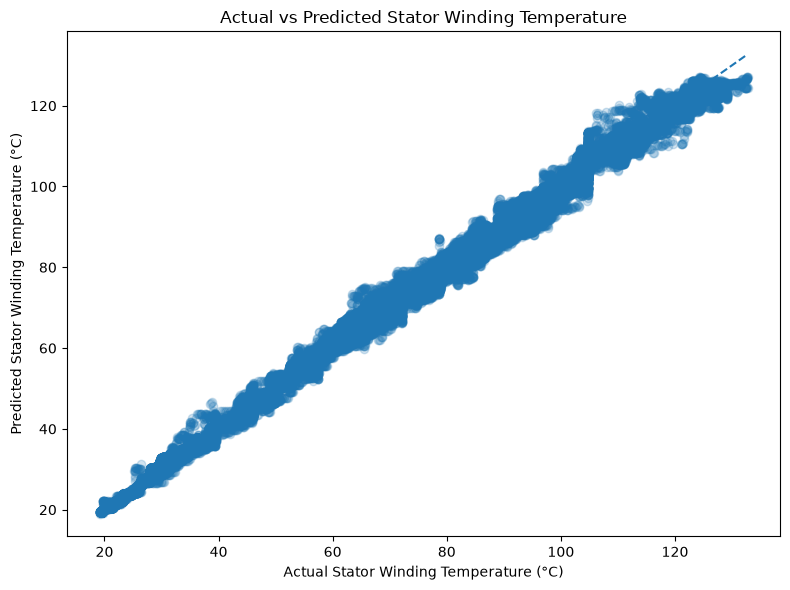

In [23]:
# Generate predictions on the test set
y_test_pred = final_model.predict(X_test)

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_test_pred, alpha=0.2)

# Perfect prediction line
min_temp = min(y_test.min(), y_test_pred.min())
max_temp = max(y_test.max(), y_test_pred.max())

plt.plot(
    [min_temp, max_temp],
    [min_temp, max_temp],
    linestyle="--"
)

plt.xlabel("Actual Stator Winding Temperature (°C)")
plt.ylabel("Predicted Stator Winding Temperature (°C)")
plt.title("Actual vs Predicted Stator Winding Temperature")

plt.tight_layout()
plt.savefig("../graphs/actual_vs_predicted.png", dpi=300)

plt.show()

## 8. Residual Analysis

Residuals represent the prediction error of the model.

Residual = Actual Temperature − Predicted Temperature

The residual distribution is examined to identify systematic errors and
potential regions where the model performs poorly.

In [24]:
# Calculate residuals
residuals = y_test - y_test_pred

print("Residual Statistics")
print("-------------------")
print("Mean residual:", residuals.mean())
print("Std residual :", residuals.std())
print("Minimum      :", residuals.min())
print("Maximum      :", residuals.max())

Residual Statistics
-------------------
Mean residual: -0.4712162935446001
Std residual : 1.5759745539289105
Minimum      : -12.006229368353672
Maximum      : 10.680384564700006


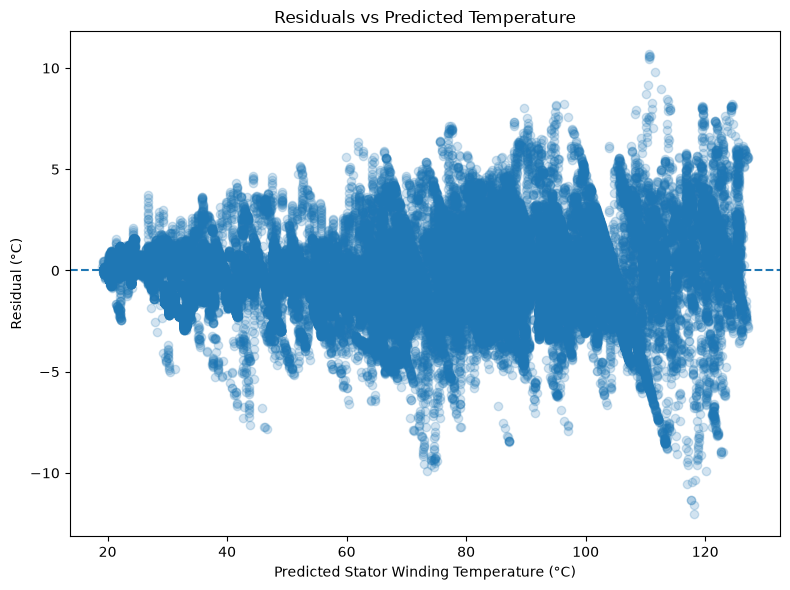

In [25]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test_pred, residuals, alpha=0.2)

plt.axhline(0, linestyle="--")

plt.xlabel("Predicted Stator Winding Temperature (°C)")
plt.ylabel("Residual (°C)")
plt.title("Residuals vs Predicted Temperature")

plt.tight_layout()
plt.savefig("../graphs/residual_analysis.png", dpi=300)

plt.show()

## 9. Feature Importance

Permutation importance is used to estimate the contribution of each input
feature to the model's predictive performance.

A larger importance value indicates that the model relies more heavily on
that feature when predicting stator winding temperature.

In [26]:
from sklearn.inspection import permutation_importance

# Calculate permutation importance on the validation set
perm_importance = permutation_importance(
    final_model,
    X_val,
    y_val,
    n_repeats=5,
    random_state=42,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance": perm_importance.importances_mean
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

print(feature_importance.to_string(index=False))

     Feature  Importance
stator_tooth   49.356260
 stator_yoke    8.769376
          pm    1.417078
         i_d    1.170421
     coolant    1.019934
      torque    0.742534
         u_q    0.599123
     ambient    0.113787
         i_q    0.057921
 motor_speed    0.027442
         u_d    0.021888


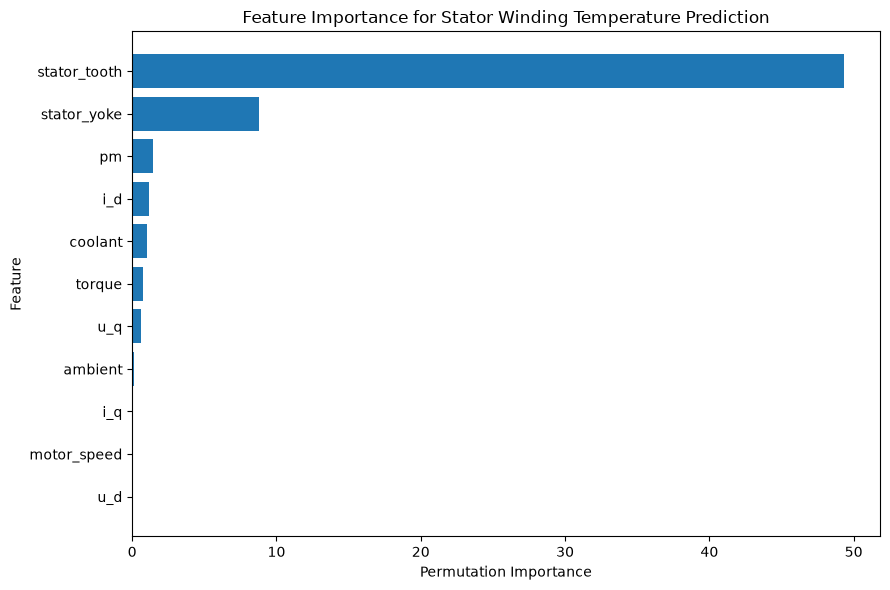

In [27]:
plt.figure(figsize=(9, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Permutation Importance")
plt.ylabel("Feature")
plt.title("Feature Importance for Stator Winding Temperature Prediction")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.savefig("../graphs/feature_importance.png", dpi=300)

plt.show()

## 10. Saving the Final Model

The final trained model is saved so that it can later be reused for prediction
without retraining the model.

In [28]:
import joblib

joblib.dump(
    final_model,
    "../models/final_temperature_model.pkl"
)

print("Final model saved successfully.")

Final model saved successfully.


## 11. Final Results and Conclusion

The motor temperature prediction task was treated as a regression problem with
stator winding temperature as the target variable.

Multiple regression models were evaluated using MAE, RMSE and R². The
HistGradientBoosting model provided the strongest validation performance and
was therefore selected for hyperparameter tuning.

The tuned model was evaluated on a completely unseen test set.

### Final Test Performance

- MAE: 1.145 °C
- RMSE: 1.644 °C
- R²: 0.99696

The results demonstrate that the final model can predict stator winding
temperature with high accuracy. Residual analysis and feature importance are
also used to understand model errors and identify the motor parameters that
contribute most strongly to temperature prediction.

The final trained model has been saved for future inference and deployment.